# 05 — Profit model: how much will an order line make or lose?

**Roadmap step 4b.** Goal: a predicted profit in dollars for the Loss-risk checker, next to
the step 4 loss-risk probability. This notebook is analysis only; the dashboard is not changed.

**Rules** (agreed before modelling, same rigor as step 4):
- Only features known when the order is placed: sales, quantity, discount, list price
  (`unit_price`), category, sub-category, region, state, ship mode, segment, order month.
  Nothing derived from profit, no customer history (step 3 tables), no IDs or names.
  Unlike step 4, **sales is allowed**: it is the price of the line, known at order time.
- Train on 2014-2016, test **once** on 2017. Hyperparameters and the top-4 feature ranking
  use only the training years (expanding windows 2014 → 2015 and 2014-15 → 2016).
- Baselines: (a) the training median profit; (b) sales × the training margin of the line's
  discount band and sub-category.
- Models: Linear Regression and Random Forest. Agreed extra rule: if the direct-profit
  forest does not beat baseline (b), also try a forest that predicts the **margin** and
  multiplies it by sales.
- Feature sets: (1) all allowed, (2) top 4 by importance, (3) top 4 without sales,
  (4) exactly the page's 4 inputs.

Code: `src/profit_model.py`. Tests: `tests/test_profit_model.py` (including a leakage guard).

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import src.loss_model as lm
import src.profit_model as pm
from src.build_database import DB_PATH, build_database

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DB_PATH.exists():
    build_database()

con = duckdb.connect(str(DB_PATH), read_only=True)
lines = pm.load_lines(con)
train, test = lm.split_by_year(lines)
print(f"train (2014-2016): {len(train):,} lines | test (2017): {len(test):,} lines")
print("allowed features:", pm.ALL_FEATURES)


def show(df, money=(), pct=(), decimals=2):
    fmt = {c: "${:,.2f}" for c in money} | {c: "{:.1%}" for c in pct}
    display(df.style.format(fmt, precision=decimals, thousands=",").hide(axis="index"))

train (2014-2016): 6,681 lines | test (2017): 3,312 lines
allowed features: ['category', 'sub_category', 'region', 'state', 'ship_mode', 'segment', 'order_month', 'sales', 'quantity', 'discount', 'unit_price']


In [2]:
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "font.size": 10, "text.color": TEXT,
})


def add_titles(fig, title, subtitle, top=0.86):
    fig.text(0.015, 0.965, title, fontsize=12, fontweight="bold", color=TEXT, va="top")
    fig.text(0.015, 0.895, subtitle, fontsize=9, color=TEXT_2, va="top")
    fig.tight_layout(rect=(0, 0, 1, top))


def save(fig, name):
    fig.savefig(FIG_DIR / f"05_{name}.png", dpi=150)
    plt.show()

## 1. Profit has heavy outliers, so MAE is the main metric

Training years only.

count    6681.00
mean       28.88
std       230.43
min     -6599.98
1%       -306.14
5%        -54.60
50%         8.80
95%       171.99
99%       557.89
max      8399.98

The 1% of lines with the largest |profit| carry 27.5% of all absolute profit.


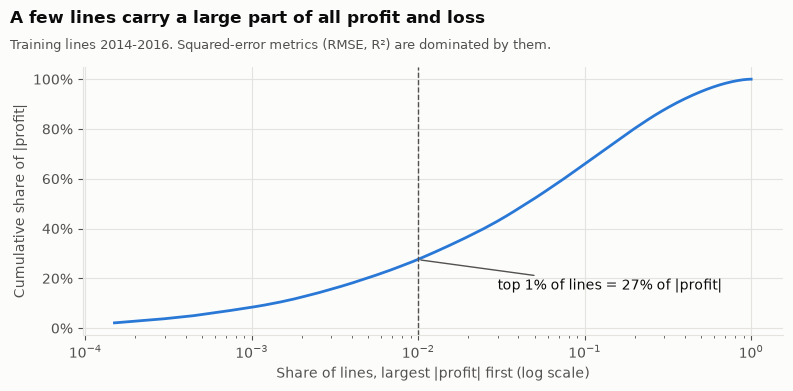

In [3]:
p = train["profit"]
print(p.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2).to_string())
abs_sorted = np.sort(p.abs().to_numpy())[::-1]
cum_share = abs_sorted.cumsum() / abs_sorted.sum()
top1 = cum_share[int(len(abs_sorted) * 0.01) - 1]
print(f"\nThe 1% of lines with the largest |profit| carry {top1:.1%} of all absolute profit.")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, len(abs_sorted) + 1) / len(abs_sorted)
ax.plot(x, cum_share, color=BLUE, lw=2)
ax.axvline(0.01, color=TEXT_2, ls="--", lw=1)
ax.annotate(f"top 1% of lines = {top1:.0%} of |profit|", (0.01, top1),
            xytext=(0.03, top1 - 0.12), color=TEXT,
            arrowprops={"arrowstyle": "-", "color": TEXT_2})
ax.set_xscale("log")
ax.set_xlabel("Share of lines, largest |profit| first (log scale)")
ax.set_ylabel("Cumulative share of |profit|")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
add_titles(fig, "A few lines carry a large part of all profit and loss",
           "Training lines 2014-2016. Squared-error metrics (RMSE, R²) are dominated by them.")
save(fig, "01_profit_concentration")

**Which metric we trust most: MAE.** A handful of lines make or lose thousands of dollars while
the median line makes a few dollars. RMSE squares the errors, so a few extreme lines can decide
it, and R² (built on squared errors) inherits that. MAE is the average miss **in dollars per
line**, the unit the page will show, and it is not driven by a few lines. RMSE and R² are still
reported, as a check on how badly each model misses the extreme lines; the median absolute error
shows the typical miss.

## 2. The page can compute Sales

The page has no Sales input, but it has quantity, discount and a list price (under "Advanced",
default = the sub-category's median training price). In the cleaned data
`unit_price = sales / (1 - discount) / quantity` (step 1 assumption: sales is recorded after
discount), so Sales = list price × quantity × (1 − discount) exactly:

In [4]:
diff = np.abs(pm.derived_sales(lines) - lines["sales"].to_numpy())
print(f"max |derived sales - sales| over all {len(lines):,} lines: {diff.max():.2e}")

max |derived sales - sales| over all 9,993 lines: 9.09e-13


## 3. Tuning on the training years

Random Forest settings are chosen by mean MAE on the two expanding-window folds. Baselines and
Linear Regression are scored on the same folds for reference.

In [5]:
def cv_baseline(make):
    maes = []
    for fit_years, val_year in lm.CV_FOLDS:
        fit = train[train["order_year"].isin(fit_years)]
        val = train[train["order_year"] == val_year]
        maes.append(np.mean(np.abs(val["profit"] - make().fit(fit).predict(val))))
    return float(np.mean(maes))


cv_a = cv_baseline(pm.MedianBaseline)
cv_b = cv_baseline(pm.MarginRuleBaseline)
tuning_all = pm.tune_forest(pm.ALL_FEATURES, train)
params_all = dict(tuning_all.loc[0, "params"])
print(f"CV MAE  baseline (a): ${cv_a:.2f} | baseline (b): ${cv_b:.2f} | "
      f"linear (all features): ${pm.cv_mae('linear', pm.ALL_FEATURES, {}, train):.2f}")
show(tuning_all.drop(columns="params"), money=["cv_mae"])

CV MAE  baseline (a): $57.98 | baseline (b): $19.44 | linear (all features): $64.27


max_depth,min_samples_leaf,cv_mae
nan,1,$25.11
16.00,1,$25.15
nan,5,$26.88
16.00,5,$26.88
8.00,5,$28.67
8.00,1,$28.90
nan,20,$33.09
16.00,20,$33.09
8.00,20,$33.48


## 4. Feature ranking (training years only) → the top 4

A forest with the tuned settings is fit on 2014-2015 and permutation importance (increase in MAE
when a feature is shuffled) is measured on 2016. One-hot columns move together, so each feature
is judged as one feature. 2017 is not read.

feature,mae_increase,std
sales,$63.95,$1.04
discount,$32.38,$1.17
unit_price,$11.75,$0.54
sub_category,$6.66,$0.24
category,$3.48,$0.20
quantity,$1.22,$0.23
state,$0.30,$0.08
region,$0.22,$0.04
ship_mode,$0.11,$0.06
segment,$-0.03,$0.04


top 4: ['sales', 'discount', 'unit_price', 'sub_category']


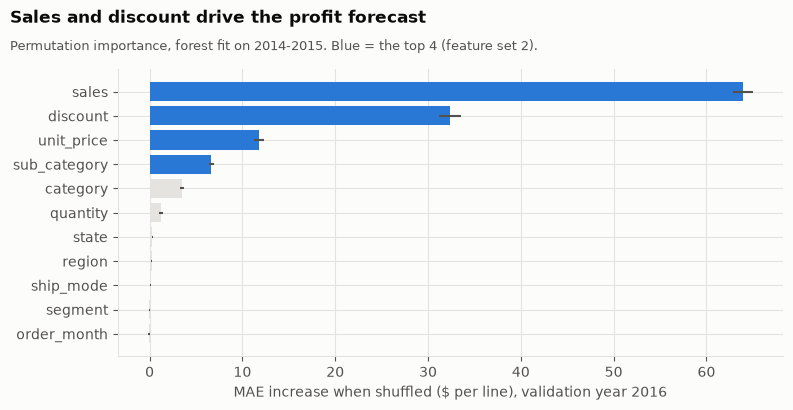

In [6]:
ranking = pm.rank_features(lines, params_all)
show(ranking, money=["mae_increase", "std"])
top4 = ranking["feature"].head(4).tolist()
print("top 4:", top4)

fig, ax = plt.subplots(figsize=(8, 4.2))
r = ranking.iloc[::-1]
colors = [BLUE if f in top4 else GRID for f in r["feature"]]
ax.barh(r["feature"], r["mae_increase"], xerr=r["std"], color=colors, ecolor=TEXT_2)
ax.set_xlabel("MAE increase when shuffled ($ per line), validation year 2016")
add_titles(fig, "Sales and discount drive the profit forecast",
           "Permutation importance, forest fit on 2014-2015. Blue = the top 4 (feature set 2).")
save(fig, "02_feature_ranking")

In [7]:
FEATURE_SETS = {"1. All allowed": pm.ALL_FEATURES, "2. Top 4": top4}
if "sales" in top4:
    FEATURE_SETS["3. Top 4 without Sales"] = [f for f in top4 if f != "sales"]
FEATURE_SETS["4. Page inputs"] = pm.PAGE_FEATURES
# Extra row (not one of the four planned sets): what the page can supply without new inputs
FEATURE_SETS["5. Page inputs + list price"] = pm.PAGE_FEATURES + ["unit_price"]
for name, feats in FEATURE_SETS.items():
    print(f"{name:30} {feats}  sales known or derivable: {pm.sales_derivable(feats)}")

1. All allowed                 ['category', 'sub_category', 'region', 'state', 'ship_mode', 'segment', 'order_month', 'sales', 'quantity', 'discount', 'unit_price']  sales known or derivable: True
2. Top 4                       ['sales', 'discount', 'unit_price', 'sub_category']  sales known or derivable: True
3. Top 4 without Sales         ['discount', 'unit_price', 'sub_category']  sales known or derivable: False
4. Page inputs                 ['sub_category', 'state', 'discount', 'quantity']  sales known or derivable: False
5. Page inputs + list price    ['sub_category', 'state', 'discount', 'quantity', 'unit_price']  sales known or derivable: True


Set 3 drops Sales but keeps list price, discount and sub-category; without quantity, Sales
cannot be rebuilt from it. Set 5 is an extra row: the page's 4 inputs plus the list price that
the page already has under "Advanced". From those the page can compute Sales exactly.

## 5. Does the direct-profit forest beat baseline (b)? (training years)

The agreed rule adds the margin × sales forest only if the direct-profit forest loses to
baseline (b). We first saw this on 2017 in an exploratory run; here it is checked on the
training folds alone, so the decision does not depend on the test year.

In [8]:
tuned = {}   # (feature set, model kind) -> (params, cv_mae)
for name, feats in FEATURE_SETS.items():
    t = pm.tune_forest(feats, train)
    tuned[(name, "forest")] = (dict(t.loc[0, "params"]), float(t.loc[0, "cv_mae"]))
    tuned[(name, "linear")] = ({}, pm.cv_mae("linear", feats, {}, train))
cv_direct = pd.DataFrame([{"feature set": n, "model": k, "cv_mae": v[1]}
                          for (n, k), v in tuned.items()])
show(cv_direct, money=["cv_mae"])
best_direct = cv_direct.loc[cv_direct["model"] == "forest", "cv_mae"].min()
print(f"best direct-profit forest CV MAE ${best_direct:.2f} vs baseline (b) ${cv_b:.2f} -> "
      + ("loses to (b): add the margin x sales forest" if best_direct >= cv_b
         else "beats (b) on the folds"))

feature set,model,cv_mae
1. All allowed,forest,$25.11
1. All allowed,linear,$64.27
2. Top 4,forest,$23.45
2. Top 4,linear,$59.73
3. Top 4 without Sales,forest,$37.58
3. Top 4 without Sales,linear,$69.45
4. Page inputs,forest,$57.30
4. Page inputs,linear,$69.98
5. Page inputs + list price,forest,$26.77
5. Page inputs + list price,linear,$69.72


best direct-profit forest CV MAE $23.45 vs baseline (b) $19.44 -> loses to (b): add the margin x sales forest


In [9]:
for name, feats in FEATURE_SETS.items():
    if pm.sales_derivable(feats):
        t = pm.tune_forest(feats, train, kind="margin_forest")
        tuned[(name, "margin_forest")] = (dict(t.loc[0, "params"]), float(t.loc[0, "cv_mae"]))
show(pd.DataFrame([{"feature set": n, "params": str(v[0]), "cv_mae": v[1]}
                   for (n, k), v in tuned.items() if k == "margin_forest"]), money=["cv_mae"])

feature set,params,cv_mae
1. All allowed,"{'max_depth': None, 'min_samples_leaf': 1}",$14.78
2. Top 4,"{'max_depth': None, 'min_samples_leaf': 1}",$13.35
5. Page inputs + list price,"{'max_depth': None, 'min_samples_leaf': 1}",$14.22


### Is "margin × Sales" supported on the validation years, not only on 2017?

MAE on each training-year validation fold separately (fit on 2014 → score 2015; fit on
2014-2015 → score 2016), with each model's tuned settings. 2017 is not used here.

In [10]:
def fold_rows(label, feature_set, predict_fold):
    row = {"feature set": feature_set, "model": label}
    for fit_years, val_year in lm.CV_FOLDS:
        fit = train[train["order_year"].isin(fit_years)]
        val = train[train["order_year"] == val_year]
        row[f"mae_{val_year}"] = float(np.mean(np.abs(val["profit"] - predict_fold(fit, val))))
    return row


KIND_LABEL = {"forest": "Random Forest (profit)", "margin_forest": "Random Forest (margin x sales)"}
fold_table = [fold_rows("Baseline (b)", "-", lambda f, v: pm.MarginRuleBaseline().fit(f).predict(v))]
for (name, kind), (params, _) in tuned.items():
    if kind in KIND_LABEL and pm.sales_derivable(FEATURE_SETS[name]):
        fold_table.append(fold_rows(
            KIND_LABEL[kind], name,
            lambda f, v, k=kind, n=name, p=params: pm.fit_predict(k, FEATURE_SETS[n], p, f, v)))
fold_table = pd.DataFrame(fold_table)
show(fold_table, money=["mae_2015", "mae_2016"])

margin_rows = fold_table[fold_table["model"] == KIND_LABEL["margin_forest"]].set_index("feature set")
profit_rows = fold_table[fold_table["model"] == KIND_LABEL["forest"]].set_index("feature set")
b_row = fold_table.iloc[0]
for year in (2015, 2016):
    col = f"mae_{year}"
    beats_b = (margin_rows[col] < b_row[col]).all()
    beats_profit = (margin_rows[col] < profit_rows.loc[margin_rows.index, col]).all()
    print(f"{year}: margin x sales forest beats baseline (b) in every set: {beats_b}; "
          f"beats the direct-profit forest on the same features: {beats_profit}")

feature set,model,mae_2015,mae_2016
-,Baseline (b),$19.65,$19.24
1. All allowed,Random Forest (profit),$25.01,$25.20
2. Top 4,Random Forest (profit),$23.70,$23.19
5. Page inputs + list price,Random Forest (profit),$26.00,$27.54
1. All allowed,Random Forest (margin x sales),$15.46,$14.10
2. Top 4,Random Forest (margin x sales),$14.06,$12.65
5. Page inputs + list price,Random Forest (margin x sales),$14.79,$13.65


2015: margin x sales forest beats baseline (b) in every set: True; beats the direct-profit forest on the same features: True
2016: margin x sales forest beats baseline (b) in every set: True; beats the direct-profit forest on the same features: True


## 6. Results on 2017 (the test year, used once)

Every model is refit on 2014-2016 with its tuned settings. "vs (b)" is the paired order-level
bootstrap of MAE(model) − MAE(baseline b): an interval entirely below 0 means the model is
better. Baselines do not use the feature sets, so they appear once.

In [11]:
MODEL_NAMES = {"linear": "Linear Regression", "forest": "Random Forest (profit)",
               "margin_forest": "Random Forest (margin x sales)"}
base_a = pm.MedianBaseline().fit(train).predict(test)
base_b = pm.MarginRuleBaseline().fit(train).predict(test)
predictions = {("-", "Baseline (a): training median"): base_a,
               ("-", "Baseline (b): sales x band/sub-category margin"): base_b}
for (name, kind), (params, _) in tuned.items():
    predictions[(name, MODEL_NAMES[kind])] = pm.fit_predict(kind, FEATURE_SETS[name], params,
                                                           train, test)

rows = []
for (name, model), pred in predictions.items():
    d = pm.bootstrap_mae_difference(test, pred, base_b)
    rows.append({"feature set": name, "model": model, **pm.metrics(test["profit"], pred),
                 "vs_b": d["difference"], "vs_b_low": d["ci_low"], "vs_b_high": d["ci_high"]})
set_order = {"-": 0, **{n: i + 1 for i, n in enumerate(FEATURE_SETS)}}
model_order = {m: i for i, m in enumerate(MODEL_NAMES.values())}
results = (pd.DataFrame(rows)
           .assign(_s=lambda d: d["feature set"].map(set_order),
                   _m=lambda d: d["model"].map(model_order).fillna(-1))
           .sort_values(["_s", "_m"]).drop(columns=["_s", "_m"]).reset_index(drop=True))
show(results, money=["mae", "rmse", "median_ae", "vs_b", "vs_b_low", "vs_b_high"], decimals=3)
na = [n for n, f in FEATURE_SETS.items() if not pm.sales_derivable(f)]
print("margin x sales forest not possible (no sales, and no list price + quantity):", na)

feature set,model,mae,rmse,r2,median_ae,vs_b,vs_b_low,vs_b_high
-,Baseline (a): training median,$58.23,$242.61,-0.006,$10.66,$41.90,$35.33,$49.42
-,Baseline (b): sales x band/sub-category margin,$16.33,$62.10,0.934,$2.47,$0.00,$0.00,$0.00
1. All allowed,Linear Regression,$62.66,$174.10,0.482,$35.80,$46.33,$42.01,$51.26
1. All allowed,Random Forest (profit),$19.14,$112.33,0.784,$1.79,$2.81,$0.10,$6.18
1. All allowed,Random Forest (margin x sales),$11.54,$40.92,0.971,$1.53,$-4.79,$-6.36,$-3.14
2. Top 4,Linear Regression,$59.54,$177.90,0.459,$27.05,$43.21,$38.80,$48.53
2. Top 4,Random Forest (profit),$16.01,$81.18,0.887,$1.46,$-0.32,$-2.04,$1.99
2. Top 4,Random Forest (margin x sales),$9.56,$39.10,0.974,$1.18,$-6.77,$-8.54,$-5.07
3. Top 4 without Sales,Linear Regression,$68.36,$214.35,0.214,$35.60,$52.03,$46.70,$58.39
3. Top 4 without Sales,Random Forest (profit),$35.61,$158.61,0.570,$7.45,$19.28,$15.23,$24.18


margin x sales forest not possible (no sales, and no list price + quantity): ['3. Top 4 without Sales', '4. Page inputs']


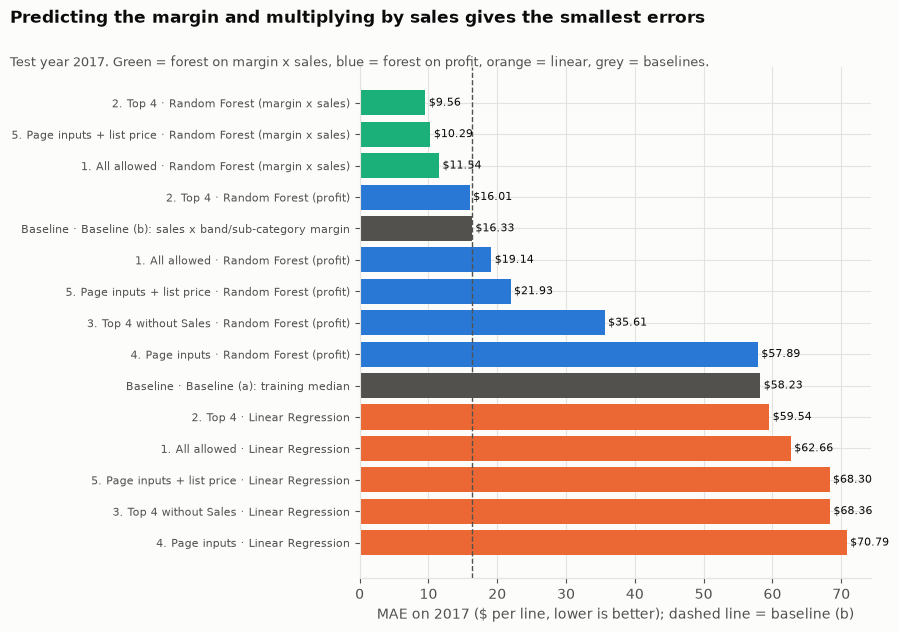

In [12]:
plot = results.copy()
plot["label"] = plot["feature set"].replace("-", "Baseline") + " · " + plot["model"]
plot = plot.sort_values("mae", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
color = plot["model"].map({MODEL_NAMES["margin_forest"]: AQUA, MODEL_NAMES["forest"]: BLUE,
                           MODEL_NAMES["linear"]: ORANGE}).fillna(TEXT_2)   # baselines grey
ax.barh(plot["label"], plot["mae"], color=color)
ax.axvline(results.loc[results["model"].str.startswith("Baseline (b)"), "mae"].iloc[0],
           color=TEXT_2, ls="--", lw=1)
for y, v in enumerate(plot["mae"]):
    ax.text(v + 0.5, y, f"${v:.2f}", va="center", fontsize=8, color=TEXT)
ax.set_xlabel("MAE on 2017 ($ per line, lower is better); dashed line = baseline (b)")
ax.tick_params(axis="y", labelsize=8)
add_titles(fig, "Predicting the margin and multiplying by sales gives the smallest errors",
           "Test year 2017. Green = forest on margin x sales, blue = forest on profit, "
           "orange = linear, grey = baselines.", top=0.9)
save(fig, "03_mae_by_model")

### Smaller feature sets vs. all allowed features (2017)

The recommendation rule (fixed in the plan): the smallest feature set the page can supply whose
MAE is not clearly worse than "all allowed" (bootstrap interval of the difference entirely above
0) and which beats baseline (b). Compared within the margin × sales forest, the best model kind:

In [13]:
best_all = predictions[("1. All allowed", MODEL_NAMES["margin_forest"])]
rows = []
for name in FEATURE_SETS:
    key = (name, MODEL_NAMES["margin_forest"])
    if key in predictions and name != "1. All allowed":
        d = pm.bootstrap_mae_difference(test, predictions[key], best_all)
        rows.append({"feature set": name, "features": ", ".join(FEATURE_SETS[name]),
                     "mae_minus_all": d["difference"], "ci_low": d["ci_low"],
                     "ci_high": d["ci_high"], "clearly_worse": d["ci_low"] > 0})
show(pd.DataFrame(rows), money=["mae_minus_all", "ci_low", "ci_high"], decimals=3)
d = pm.bootstrap_mae_difference(test, predictions[("2. Top 4", MODEL_NAMES["margin_forest"])],
                                predictions[("5. Page inputs + list price",
                                             MODEL_NAMES["margin_forest"])])
print(f"Top 4 minus (page inputs + list price): ${d['difference']:.2f} "
      f"[{d['ci_low']:.2f}, {d['ci_high']:.2f}]")

feature set,features,mae_minus_all,ci_low,ci_high,clearly_worse
2. Top 4,"sales, discount, unit_price, sub_category",$-1.98,$-2.75,$-1.23,False
5. Page inputs + list price,"sub_category, state, discount, quantity, unit_price",$-1.25,$-1.92,$-0.54,False


Top 4 minus (page inputs + list price): $-0.73 [-1.94, 0.28]


### What if the user leaves list price at the default?

On the page, list price defaults to the sub-category's median training price. To see what that
costs, the candidates are scored on 2017 with every line's list price replaced by that median
(and Sales recomputed from it), which is what the page would do by default. Baseline (b) is
shown the same way for reference.

In [14]:
median_price = train.groupby("sub_category")["unit_price"].median()
default_price = test.assign(unit_price=test["sub_category"].map(median_price))
default_price = default_price.assign(sales=pm.derived_sales(default_price))
rule_b = pm.MarginRuleBaseline().fit(train)
rows = []
for label, data_ in [("real list price", test), ("sub-category default price", default_price)]:
    rows.append({"model": "Baseline (b)", "list price used": label,
                 **pm.metrics(test["profit"].to_numpy(), rule_b.predict(data_))})
for name in ["2. Top 4", "5. Page inputs + list price"]:
    params, _ = tuned[(name, "margin_forest")]
    model = pm.MarginForest(FEATURE_SETS[name], **params).fit(train)
    for label, data_ in [("real list price", test), ("sub-category default price", default_price)]:
        rows.append({"model": f"Margin x sales forest, {name}", "list price used": label,
                     **pm.metrics(test["profit"].to_numpy(), model.predict(data_))})
price_table = pd.DataFrame(rows)
show(price_table, money=["mae", "rmse", "median_ae"], decimals=3)

model,list price used,mae,rmse,r2,median_ae
Baseline (b),real list price,$16.33,$62.10,0.934,$2.47
Baseline (b),sub-category default price,$47.22,$211.34,0.236,$9.24
"Margin x sales forest, 2. Top 4",real list price,$9.56,$39.10,0.974,$1.18
"Margin x sales forest, 2. Top 4",sub-category default price,$48.68,$212.02,0.231,$9.19
"Margin x sales forest, 5. Page inputs + list price",real list price,$10.29,$41.61,0.970,$1.33
"Margin x sales forest, 5. Page inputs + list price",sub-category default price,$48.50,$211.29,0.237,$9.09


## 7. What drives the recommended model's predictions (2017, reporting only)

Permutation importance (MAE increase in dollars, all 2017 lines) and SHAP. The forest explains
the margin; multiplying each margin contribution by the line's sales gives its contribution in
dollars, which still adds up to the predicted profit. One-hot columns are summed back into their
feature.

**SHAP is computed on a fixed random sample of 500 test lines** (`random_state=42`). The tuned
forest has unlimited depth, and exact tree SHAP on all 3,312 lines takes too long; importance is
reporting only, so a fixed sample is enough to rank four features.

feature,mae_increase,std,mean_abs_shap
sales,$100.69,$3.11,$1.19
discount,$59.89,$4.12,$28.12
sub_category,$26.77,$1.57,$18.18
unit_price,$6.68,$0.35,$3.96


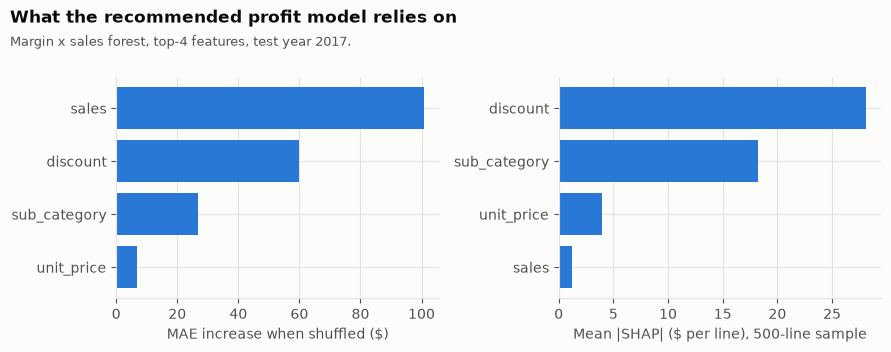

In [15]:
REC = "2. Top 4"
SHAP_SAMPLE_SIZE, SHAP_SEED = 500, 42
rec_params, _ = tuned[(REC, "margin_forest")]
rec_model = pm.MarginForest(FEATURE_SETS[REC], **rec_params).fit(train)
perm = pm.permutation_mae_increase(rec_model.predict, test, FEATURE_SETS[REC])
shap_lines = test.sample(SHAP_SAMPLE_SIZE, random_state=SHAP_SEED)
base, dollars = pm.explain_margin_forest(rec_model, shap_lines)
assert np.allclose(base + dollars.sum(axis=1).to_numpy(), rec_model.predict(shap_lines), atol=1e-6)
shap_rank = pm.shap_ranking(dollars)
show(perm.merge(shap_rank, on="feature"), money=["mae_increase", "std", "mean_abs_shap"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (df, col, label) in zip(axes, [(perm, "mae_increase", "MAE increase when shuffled ($)"),
                                       (shap_rank, "mean_abs_shap",
                                        "Mean |SHAP| ($ per line), 500-line sample")]):
    d = df.iloc[::-1]
    ax.barh(d["feature"], d[col], color=BLUE)
    ax.set_xlabel(label)
add_titles(fig, "What the recommended profit model relies on",
           "Margin x sales forest, top-4 features, test year 2017.", top=0.82)
save(fig, "04_importance")

## 8. Where the errors are (2017)

In [16]:
rec_pred = rec_model.predict(test)
err = test[["sales", "profit"]].assign(
    size=pd.qcut(test["sales"], 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"]),
    outcome=np.where(test["profit"] < 0, "loss line", "profit line"),
    rule_b=np.abs(test["profit"] - base_b),
    model=np.abs(test["profit"] - rec_pred))
for by in ["size", "outcome"]:
    show(err.groupby(by, observed=True)
         .agg(lines=("profit", "size"), mae_rule_b=("rule_b", "mean"), mae_model=("model", "mean"))
         .reset_index(), money=["mae_rule_b", "mae_model"])

size,lines,mae_rule_b,mae_model
smallest 25%,828,$0.97,$0.50
25-50%,828,$2.54,$1.50
50-75%,828,$9.57,$6.74
largest 25%,828,$52.24,$29.50


outcome,lines,mae_rule_b,mae_model
loss line,620,$35.40,$15.55
profit line,"2,692",$11.94,$8.18


### Expected error by line size (Sales deciles)

The largest quartile spans lines from a few hundred to $14,000 in Sales, so one average hides
how the error grows with size. The dashboard shows the user this decile table's MAE for a line of
the same size (`pm.error_by_sales_band`, the same function the app uses).

In [17]:
deciles = pm.error_by_sales_band(test["sales"].to_numpy(), test["profit"].to_numpy(), rec_pred)
show(deciles, money=["sales_low", "sales_high", "mae"])

band,sales_low,sales_high,lines,mae
0,$0.44,$8.00,332,$0.30
1,$8.00,$13.50,331,$0.52
2,$13.50,$20.96,331,$0.75
3,$20.96,$33.66,331,$1.17
4,$33.66,$53.81,331,$2.25
5,$53.81,$88.86,331,$4.52
6,$88.86,$155.31,331,$7.63
7,$155.31,$259.14,332,$11.17
8,$259.14,$526.57,330,$17.54
9,$526.57,"$13,999.96",332,$49.68


## 9. Does the predicted profit agree with the step 4 loss risk? (2017)

On the page both numbers will sit side by side. The step 4 Random Forest (tuned settings,
trained on 2014-2016) flags a line at probability ≥ 50%; the profit model says "loss" when the
predicted profit is below 0.

In [18]:
loss_model = lm.train_final_model(con)
_, loss_test = lm.split_by_year(lm.load_lines(con))
assert (loss_test["row_id"].to_numpy() == test["row_id"].to_numpy()).all()
risk = loss_model["forest"].predict_proba(loss_test[lm.FEATURES])[:, 1]
flags = pd.DataFrame({"risk >= 50%": risk >= 0.5, "predicted profit < 0": rec_pred < 0,
                      "actual loss": test["profit"].to_numpy() < 0})
agree = (flags["risk >= 50%"] == flags["predicted profit < 0"]).mean()
print(f"The two models agree on loss vs. no loss for {agree:.1%} of 2017 lines.")
print(f"Matches the actual outcome: loss risk {(flags['risk >= 50%'] == flags['actual loss']).mean():.1%}, "
      f"profit sign {(flags['predicted profit < 0'] == flags['actual loss']).mean():.1%}.")
display(pd.crosstab(flags["risk >= 50%"], flags["predicted profit < 0"]))

The two models agree on loss vs. no loss for 96.4% of 2017 lines.
Matches the actual outcome: loss risk 95.1%, profit sign 96.0%.


predicted profit < 0,False,True
risk >= 50%,,
False,2644,59
True,60,549


When the two disagree, which one is right? (`pm.disagreement_stats`, also used by the dashboard
to explain a disagreement to the user.)

In [19]:
stats = pm.disagreement_stats(risk, rec_pred, test["profit"].to_numpy())
print(f"Disagreements: {stats['disagree']} of {stats['lines']:,} lines ({stats['share']:.1%}). "
      f"On those lines the profit sign matched the actual outcome {stats['profit_sign_right']:.0%} "
      f"of the time, the loss-risk flag {stats['loss_model_right']:.0%}.")

Disagreements: 119 of 3,312 lines (3.6%). On those lines the profit sign matched the actual outcome 63% of the time, the loss-risk flag 37%.


## Insight and recommendation

**Answer.** A line's profit can be forecast well from order-time information, **but only if the
price is known.** The best model predicts the line's margin with a Random Forest and multiplies
it by Sales: on 2017 its MAE is **$9.56 per line** (R² 0.974), against $16.33 for the simple rule
(baseline b, interval of the difference −$8.54 to −$5.07) and $58.23 for the median.

- **Margin × Sales, not profit directly.** Profit scales with the size of the line, so predicting it
  directly wastes the forest's splits on scale: the direct-profit forest only ties the rule at best
  ($16.01) and Linear Regression is no better than the median. The margin × Sales forest wins on
  both training-year validation folds (2015: $14.06 vs. $19.65 for the rule; 2016: $12.65 vs.
  $19.24) and again on 2017, so the choice does not rest on the test year.
- **Four inputs are enough.** The top 4 by training-year importance (Sales, discount, list price,
  sub-category) are slightly *better* than all 11 features (−$1.98, interval −$2.75 to −$1.23):
  the extra features add noise. State, region, ship mode, segment and month add nothing.
- **Price is the key input.** The page's current 4 inputs have no price and do no better than the
  median ($57.89). Left at the sub-category default list price, the recommended model's MAE rises
  from **$9.56 to $48.68**, worse than the simple rule with the real price.
- **Error grows with line size**: from $0.30 on the smallest 10% of lines to $49.68 on the
  largest 10% (Sales above ~$527). On loss lines the error falls from $35.40 (rule) to $15.55.
- **Consistent with the step 4 model.** Profit sign and loss risk (≥ 50%) agree on 96.4% of 2017
  lines. On the 119 lines where they disagree, the profit sign matched the outcome 63% of the time
  and the loss-risk flag 37%, so a disagreement mostly means a thin, uncertain margin.
- SHAP and permutation importance rank Sales differently because Sales acts mainly as the
  multiplier: permutation counts that, SHAP (which explains the margin, scaled to dollars) does
  not. Discount and sub-category drive the margin itself.

**Recommendation for the Loss-risk checker:** use the margin × Sales forest on the **top-4 feature
set**. The page computes Sales = list price × quantity × (1 − discount), so its inputs become
sub-category, discount, quantity and list price; state stays only for the loss-risk model. **List
price must be a visible input**; with the default price the forecast is far less accurate, and the
page must say so.

*Caveats:* one test year; the Sales formula relies on the step 1 assumption that Sales is recorded
after discount (it holds exactly in this data); SHAP was computed on a fixed 500-line sample.

In [20]:
con.close()